# Battery storage optimization on the French power market

Day-ahead arbitrage, price uncertainty, risk management (CVaR, drawdown) and primary reserve (FCR) for a
**50 MW / 100 MWh** battery, on French market data **2023-2025**. Every setting is chosen on 2024; 2025 is an
out-of-sample test.

| 2025 (out of sample) | Profit | |
|---|---|---|
| Perfect foresight, arbitrage only | €1.76M | theoretical ceiling |
| Deterministic (ARX forecast) | €1.23M | 70% of the ceiling |
| Risk-averse, mean-CVaR (λ = 0.375) | €1.21M | −2% profit, +18% on the 10% worst days |
| Arbitrage + FCR, λ = 0.375 | €3.64M | including the battery's own impact on the FCR price |

**Takeaways.** Risk sits on **calm days**, not crisis days. Risk aversion is cheap and statistically significant.
FCR dominates revenue, but the battery itself lowers the French FCR price by about a quarter: ignoring it would
overstate the 2025 revenue by 25% (€0.9M).

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from IPython.display import HTML, display

from bess import config, plots
from bess.analysis import block_bootstrap, daily_profits, metrics, split_period, volatility_quintiles
from bess.data import daily_spread, load_fcr, load_fcr_curves, load_prices
from bess.stochastic import cvar

R = config.RESULTS
CAL = json.loads((R / "calibration.json").read_text())
LAM, DD = CAL["lambda"], CAL["drawdown_pct"]
LAM_NAME = f"stochastic_lam{LAM:g}"
MAIN = ["perfect_foresight", "deterministic", LAM_NAME]
SHORT = {"perfect_foresight": "Perfect foresight", "deterministic": "Deterministic",
         "stochastic_lam0": "Stochastic λ = 0", LAM_NAME: f"Stochastic λ = {LAM:g}", "fcr_only": "FCR only"}

def table(df, formats):
    # Format a small table as strings: {column: format}
    out = df[list(formats)].copy().rename_axis(columns=None)
    for col, f in formats.items():
        out[col] = out[col].map(lambda v, f=f: "—" if pd.isna(v) else f.format(v))
    return out

prices = load_prices()
spread = daily_spread(prices)
bt = pd.read_csv(R / "backtest.csv", parse_dates=["day"])
fcr = pd.read_csv(R / "fcr.csv", parse_dates=["day"])
m_cal = pd.read_csv(R / "metrics_2024.csv", index_col=0)
m_test = pd.read_csv(R / "metrics_2025.csv", index_col=0)

## 1. Data and protocol

French day-ahead prices from [Energy-Charts](https://energy-charts.info) (CC BY 4.0, source Bundesnetzagentur |
SMARD.de; 15-minute prices since October 2025 averaged to hourly). FCR results and anonymous bid lists from
[regelleistung.net](https://www.regelleistung.net).

| Period | Role |
|---|---|
| 2023 | warm-up (forecast history) |
| 2024 | **calibration**: every setting is chosen here |
| 2025 | **test**: settings frozen |

,Mean price (€/MWh),Negative hours,Median daily spread (€/MWh),"FCR, 1 MW all year (k€)"
year,,,,
2023,97,147,77,66
2024,58,352,76,42
2025,61,513,86,92


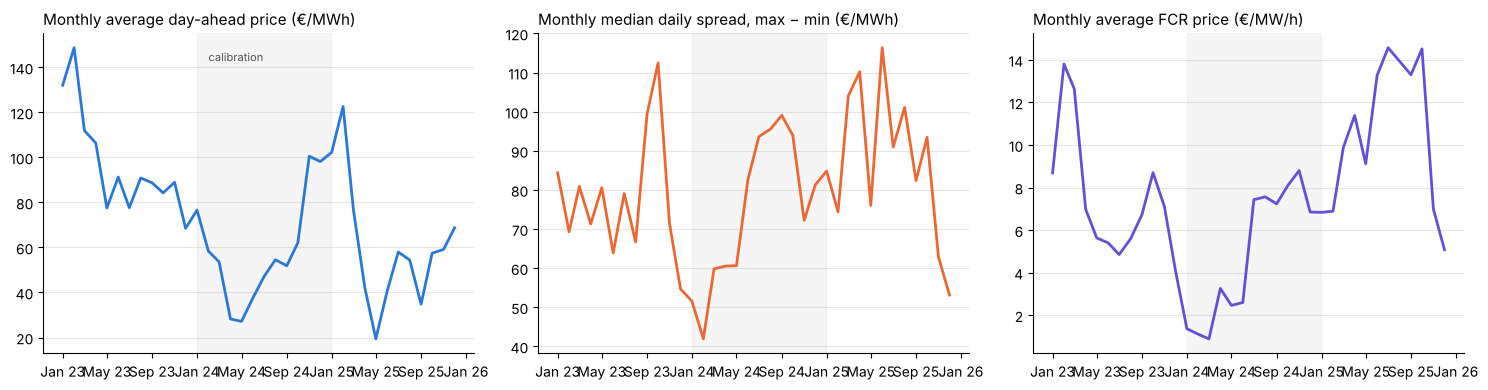

In [2]:
summary = pd.read_csv(R / "data_summary.csv", index_col="year")
display(table(summary, {"mean_price": "{:.0f}", "negative_hours": "{:.0f}", "median_daily_spread": "{:.0f}",
                        "fcr_keur_per_mw_year": "{:.0f}"}).rename(columns={
    "mean_price": "Mean price (€/MWh)", "negative_hours": "Negative hours",
    "median_daily_spread": "Median daily spread (€/MWh)", "fcr_keur_per_mw_year": "FCR, 1 MW all year (k€)"}))
plots.plot_data_overview(prices, spread, load_fcr());

Prices fell after the crisis but **daily spreads stay high** (€76-86/MWh): a battery earns the spread, not the level.
Negative hours multiply with solar (147 → 513). FCR collapsed in 2024 as batteries flooded the market, then
partly recovered in 2025.

## 2. Battery model and perfect-foresight benchmark

50 MW, 100 MWh, state of charge 10-90% (80 MWh usable), round-trip efficiency 88%, back to 50% at the end of each
day. Wear is a **linear cost per MWh discharged**: €100k/MWh replacement / (7,000 cycles × 0.8) ≈ **€17.9/MWh**.

**MILP** (PuLP + HiGHS), for each hour $t$: charge $c_t$, discharge $d_t$, energy $e_t$, binary $b_t$:

$$\max \sum_t p_t (d_t - c_t) - c_{deg} d_t \quad \text{s.t.} \quad e_{t+1} = e_t + \sqrt{\eta}\,c_t - d_t/\sqrt{\eta},
\quad c_t \le P b_t,\; d_t \le P (1-b_t)$$

The binary forbids charging and discharging at once (otherwise profitable with negative prices).

,Daily horizon (k€),Yearly horizon (k€),Gain of the yearly horizon
year,,,
2024,"1,383","1,661",+20%
2025,"1,760","2,078",+18%


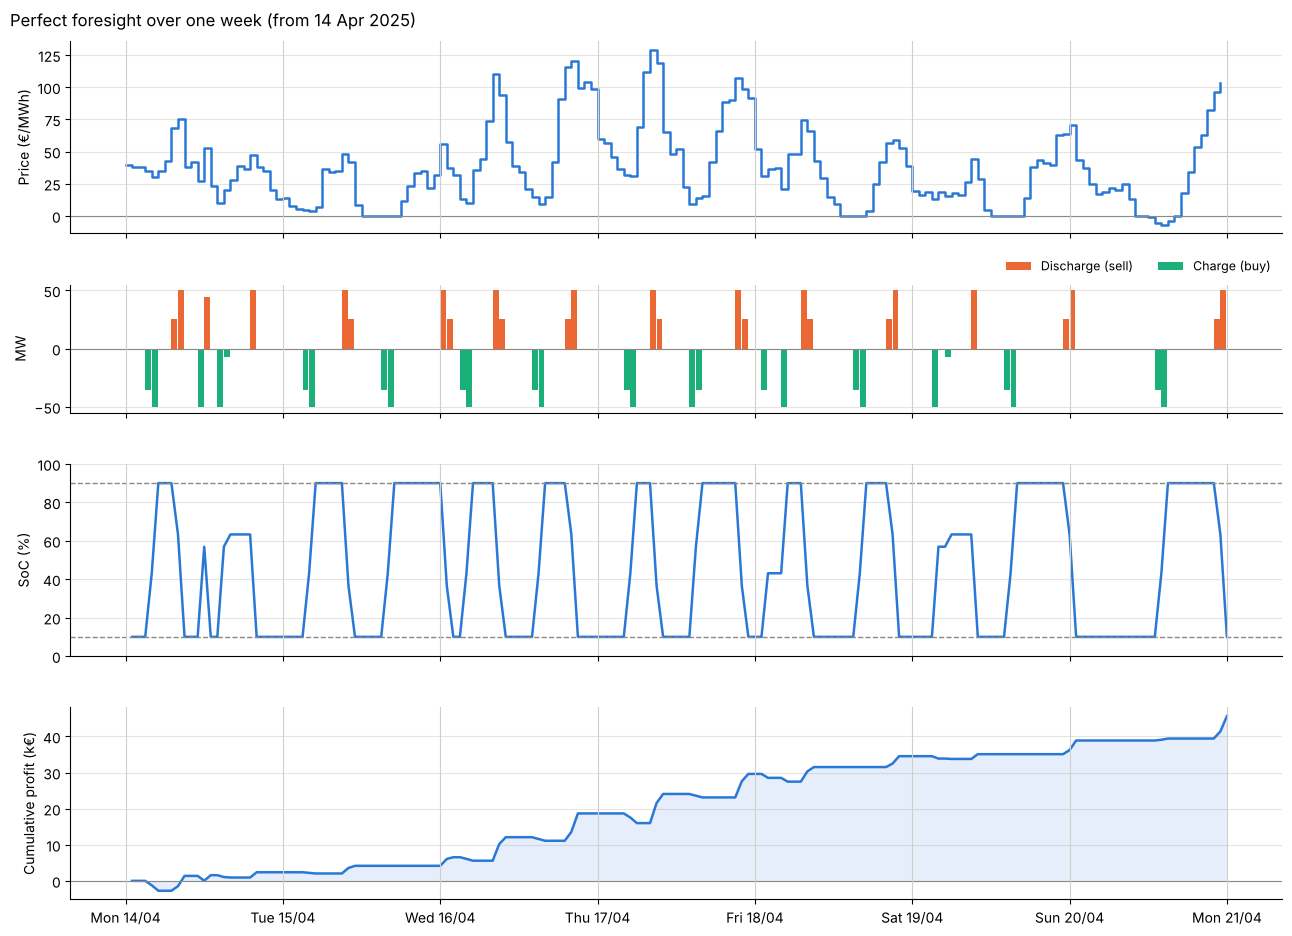

In [3]:
pf = pd.read_csv(R / "perfect_foresight.csv").pivot(index="year", columns="horizon", values="profit_keur")
pf["gain"] = pf["year"] / pf["day"] - 1
display(table(pf, {"day": "{:,.0f}", "year": "{:,.0f}", "gain": "{:+.0%}"}).rename(columns={
    "day": "Daily horizon (k€)", "year": "Yearly horizon (k€)", "gain": "Gain of the yearly horizon"}))
plots.plot_week(pd.read_csv(R / "pf_schedule_2025.csv", index_col=0), "2025-04-14");

The ceiling is **€1.38M in 2024 and €1.76M in 2025**. The rest of the project keeps the daily horizon, which
matches the day-ahead auction (a yearly horizon would add 18-20%).

## 3. Price uncertainty and CVaR optimization

**Forecast.** On day J before noon, all prices up to the end of J are known, none of J+1. One linear regression
per hour, re-estimated daily on 56 days (ARX):

$$\hat p_{J+1,h} = \beta_0 + \beta_1 p_{J,h} + \beta_2 p_{J-1,h} + \beta_3 p_{J-6,h} + \beta_4 \min p_J
+ \beta_5 \max p_J + \text{weekday dummies}$$

It beats the naive forecast ("tomorrow = today") by 14% on 2024 (MAE €17.4 vs €20.4/MWh).


**Scenarios.** Forecast errors are strongly correlated between hours (2024, figure below): 0.89 on average between
neighbouring hours and 0.54 over all pairs, never below 0.17. Two blocks stand out, the night (0.84 within
0-5 h) and the solar hours (0.80 within 10-16 h), linked to each other at about 0.45. A day forecast too high at
10 h is very likely too high at 14 h too: drawing hours independently would give jagged days and understate the
risk of a whole bad day. So whole days are simulated: a multivariate normal fitted on the last 60 days of errors,
sampled with **Cholesky** ($\Sigma = LL^\top$, $Lz \sim \mathcal N(0,\Sigma)$). A bootstrap of past days gave the
same quality; the Gaussian version was kept because it can draw any number of distinct days.


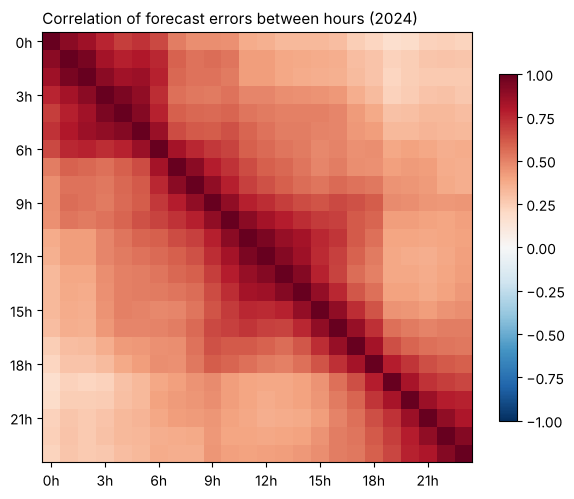

In [4]:
plots.plot_error_correlation(pd.read_csv(R / "error_correlation.csv", index_col=0));

,Coverage of the 90% interval,Actual spread,Scenario spread
method,,,
bootstrap,87.0%,76,91
gaussian,88.1%,76,93


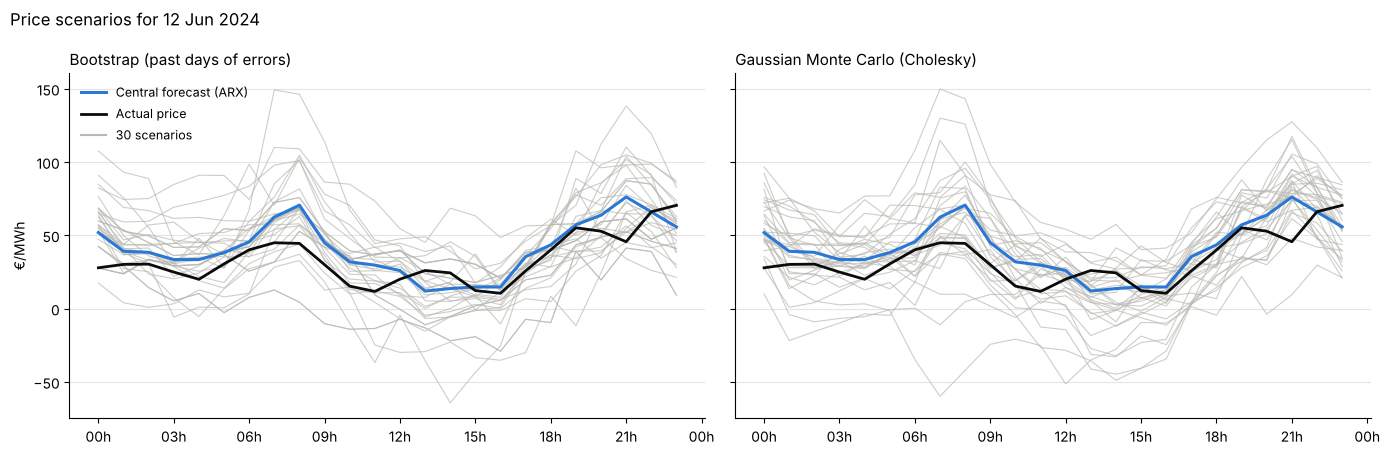

In [5]:
quality = pd.read_csv(R / "scenario_quality.csv", index_col="method")
display(table(quality, {"90% interval coverage": "{}", "daily spread real (EUR/MWh)": "{:.0f}",
                        "daily spread scenarios (EUR/MWh)": "{:.0f}"}).rename(columns={
    "90% interval coverage": "Coverage of the 90% interval", "daily spread real (EUR/MWh)": "Actual spread",
    "daily spread scenarios (EUR/MWh)": "Scenario spread"}))
plots.plot_example_scenarios(pd.read_csv(R / "example_scenarios.csv", index_col=0));

Coverage is correct (87-88%), but scenarios **overestimate the daily spread by about 20%**, which makes the
optimizer slightly optimistic.

**How many scenarios?** Schedules optimized on K scenarios, then paid on 5,000 fresh draws: the optimizer's
optimism falls from 11% (K = 30) to 0.7% (K = 200). **Kept: K = 200, α = 90%.**

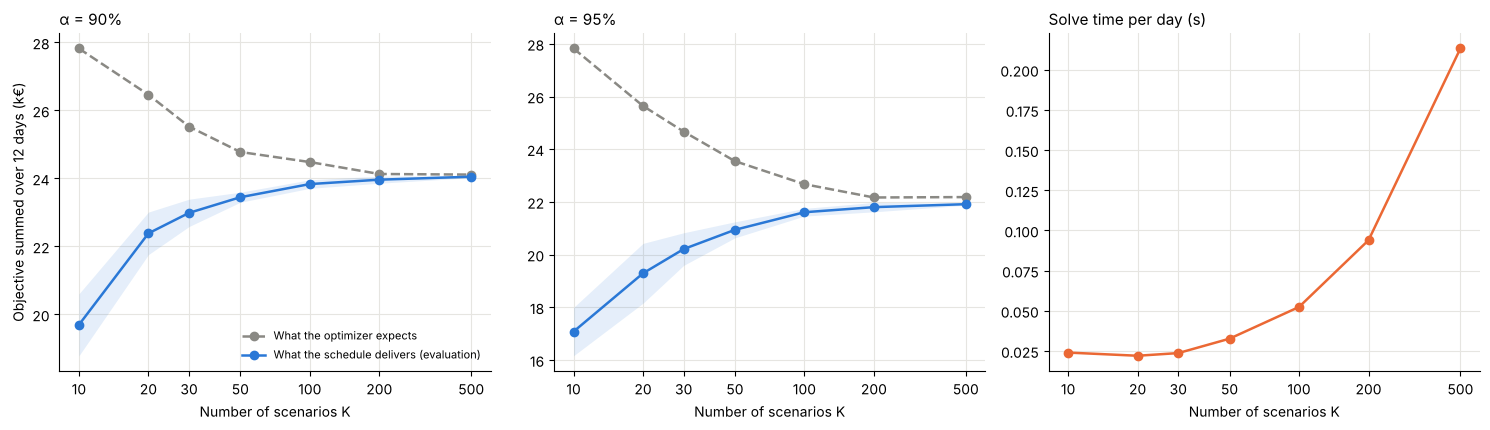

In [6]:
from bess.convergence import summarize
plots.plot_convergence(summarize(pd.read_csv(R / "convergence.csv")));

**Mean-CVaR.** One schedule for all scenarios (decided before prices are known). CVaR 90% = mean of the 10% worst
profits, linearized (Rockafellar-Uryasev):

$$\max\; (1-\lambda)\,\mathbb E[\pi] + \lambda \Big(\eta - \tfrac{1}{(1-\alpha)K}\sum_s u_s\Big), \qquad u_s \ge \eta - \pi_s,\; u_s \ge 0$$

With λ = 0 it is exactly the optimization on the mean scenario (profit is linear in prices): stochastic
optimization only pays once **risk** is priced.

## 4. Out-of-sample evaluation

Every day of 2024-2025, each strategy decides with the information of the day before and is **paid at actual
prices**. **λ rule, fixed in advance:** the most profitable λ on 2024 with at most 1 loss day in 7.
Grid: λ ∈ {0, 0.1, 0.25, 0.375, 0.5, 0.75, 1}.

Lambda chosen on 2024: 0.375


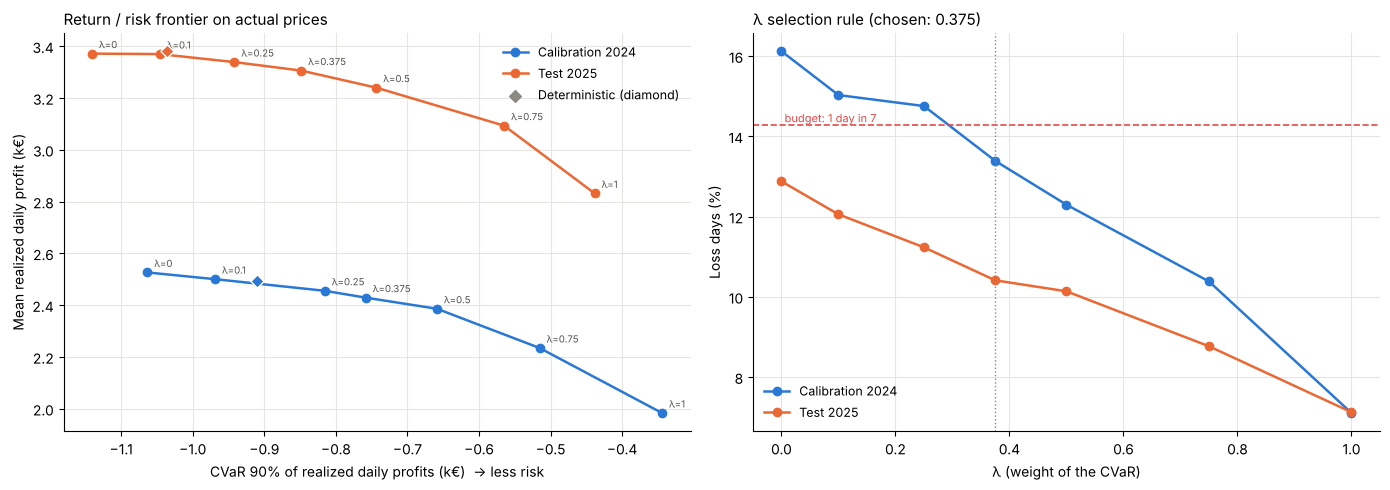

In [7]:
print(f"Lambda chosen on 2024: {LAM:g}")
plots.plot_frontier_and_rule(m_cal, m_test, LAM);

In 2024, λ ≤ 0.25 exceed the budget (15-16% of loss days); **λ = 0.375 is the most profitable one that respects
it (13.4%)**. The grid was refined with 0.375, the midpoint between 0.25 and 0.5, where the rule switches; the rule
itself is unchanged and only 2024 is used to choose. In 2025, λ = 0.375 stays within the budget (10.4%).

In [8]:
COLS = {"profit_keur": "{:,.0f}", "capture_vs_pf": "{:.0%}", "loss_days_pct": "{:.0%}",
        "cvar90_daily_eur": "{:,.0f}", "max_drawdown_keur": "{:.1f}", "cycles": "{:.0f}"}
NAMES = {"profit_keur": "Profit (k€)", "capture_vs_pf": "Share of ceiling", "loss_days_pct": "Loss days",
         "cvar90_daily_eur": "Daily CVaR 90% (€)", "max_drawdown_keur": "Max drawdown (k€)", "cycles": "Cycles"}
t = table(m_test.loc[MAIN], COLS).rename(columns=NAMES)
t.index = [SHORT[s] for s in MAIN]
t

,Profit (k€),Share of ceiling,Loss days,Daily CVaR 90% (€),Max drawdown (k€),Cycles
Perfect foresight,"1,760",100%,0%,627,0.0,518
Deterministic,"1,234",70%,13%,"-1,036",4.7,527
Stochastic λ = 0.375,"1,207",69%,10%,-849,4.0,460


### 4.1 What the stochastic strategy gains over the deterministic one

Differences λ = 0.375 minus deterministic, with 95% intervals from a moving-block bootstrap (7-day blocks, same
days for both strategies).

In [9]:
def gains(results, label):
    p = daily_profits(results)
    a, b = p[LAM_NAME], p["deterministic"]
    m = metrics(results)
    prof = block_bootstrap(a, b, lambda x: x.sum() / 1000)
    risk = block_bootstrap(a, b, lambda x: cvar(x, 0.9))
    return {"": label,
            "Profit (k€)": f"{prof['observed']:+,.0f} [{prof['ci_low']:+,.0f}; {prof['ci_high']:+,.0f}]",
            "Profit (%)": f"{a.sum() / b.sum() - 1:+.1%}",
            "Daily CVaR 90% (€)": f"{risk['observed']:+,.0f} [{risk['ci_low']:+,.0f}; {risk['ci_high']:+,.0f}]",
            "CVaR (%)": f"{(cvar(a, 0.9) - cvar(b, 0.9)) / abs(cvar(b, 0.9)):+.0%}",
            "Loss days (pts)": f"{(m.loc[LAM_NAME, 'loss_days_pct'] - m.loc['deterministic', 'loss_days_pct']) * 100:+.1f}",
            "Cycles (%)": f"{m.loc[LAM_NAME, 'cycles'] / m.loc['deterministic', 'cycles'] - 1:+.0%}"}

rows = [gains(split_period(bt, *config.CALIBRATION), "Arbitrage, 2024 (calibration)"),
        gains(split_period(bt, *config.TEST), "Arbitrage, 2025 (test)"),
        gains(split_period(fcr, *config.CALIBRATION), "Arbitrage + FCR, 2024"),
        gains(split_period(fcr, *config.TEST), "Arbitrage + FCR, 2025")]
pd.DataFrame(rows).set_index("")

,Profit (k€),Profit (%),Daily CVaR 90% (€),CVaR (%),Loss days (pts),Cycles (%)
,,,,,,
"Arbitrage, 2024 (calibration)",-24 [-48; +2],-2.6%,+152 [+29; +310],+17%,-2.7,-11%
"Arbitrage, 2025 (test)",-27 [-61; +0],-2.2%,+187 [+9; +316],+18%,-2.5,-13%
"Arbitrage + FCR, 2024",+22 [-5; +51],+1.3%,+226 [+111; +313],+93%,-1.4,-19%
"Arbitrage + FCR, 2025",+27 [-6; +56],+0.7%,+170 [+49; +259],+8%,+0.0,-27%


- **Arbitrage only**: λ = 0.375 gives up about **2% of profit** (−€24k in 2024, −€27k in 2025), a difference that is
  **not significant** (the interval reaches zero), and improves the **daily CVaR by 17-18%** (+€152 and +€187),
  which is **significant**. It also has 2.5 points fewer loss days and 11-13% fewer cycles, hence less wear.
- **With FCR**, risk aversion costs nothing (+0.7% to +1.3% profit, not significant) and still improves the CVaR
  significantly: certain FCR revenue is the hedge the CVaR term looks for.

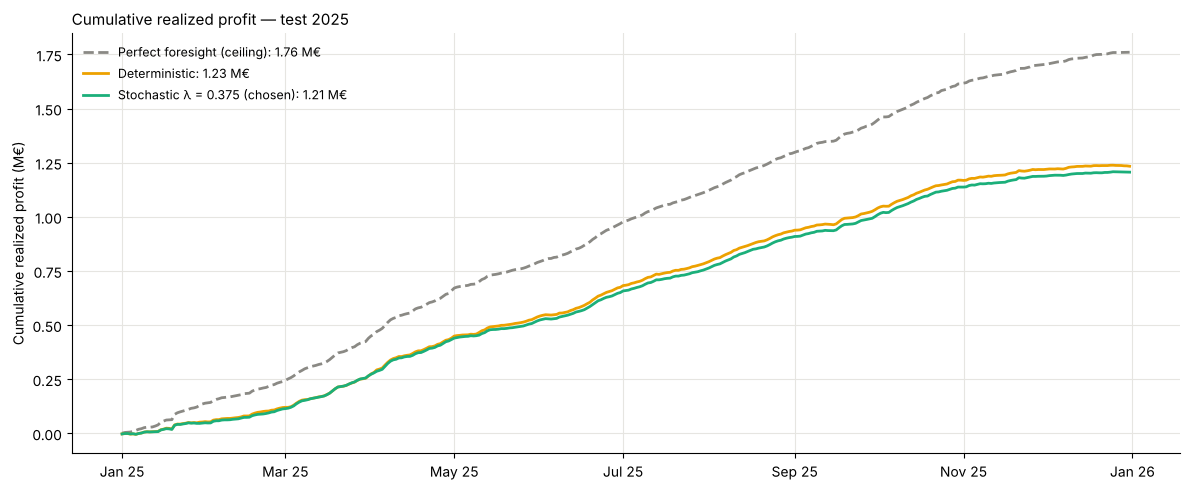

In [10]:
plots.plot_cumulative(split_period(bt, *config.TEST), MAIN, "Cumulative realized profit — test 2025",
                      lam_star=LAM, dd_star=DD);

### 4.2 Where is the risk?

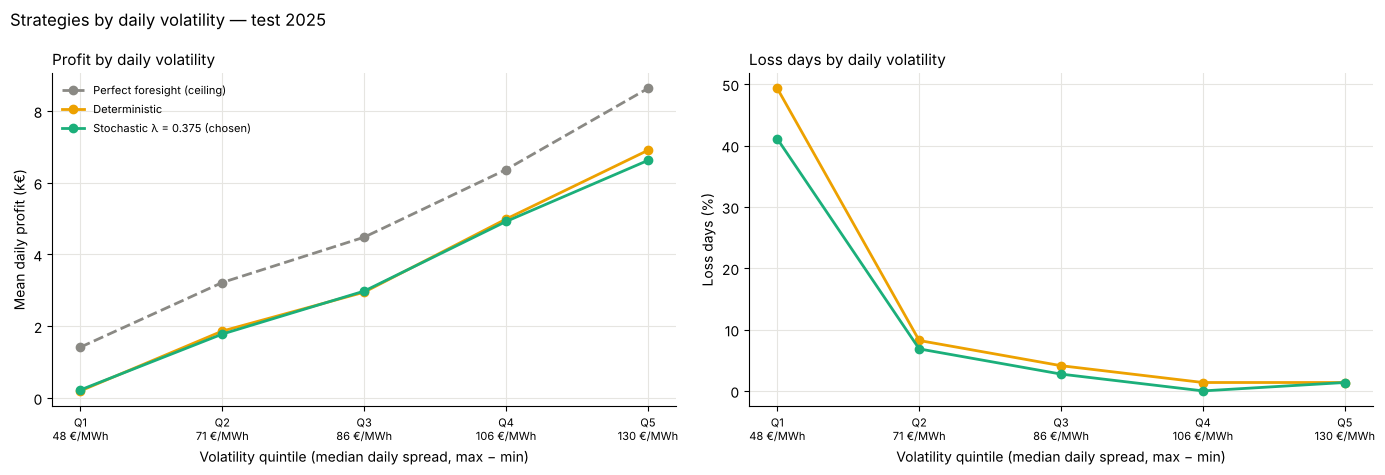

In [11]:
test = split_period(bt, *config.TEST)
vq = volatility_quintiles(test, spread)
plots.plot_volatility(vq, MAIN, "Strategies by daily volatility — test 2025", lam_star=LAM);

**Losses concentrate on calm days.** In the calmest fifth of 2025 (median spread €48/MWh), the deterministic strategy
loses money **one day in two** (49%); λ = 0.375 brings this down to 41%. On such days the forecast error is as large as
the spread itself. Profit comes from volatile days: the 20% most volatile make about 40% of the annual profit.

### 4.3 Drawdown budget (side test)

Variant: risk-neutral schedule with a daily floor $\text{CVaR}_{90\%} \ge -(\text{budget} - \text{current drawdown})$,
budget = X% of the peak cumulative profit (floor €5k), X ∈ {0.5%, 1%, 2%} chosen on the calibration period
(most profitable budget never breached). In 2024-2025 the floor binds on less than 1% of days, so it behaves like
λ = 0. Replayed on the **2022 crisis** (same Energy-Charts prices; λ and X re-chosen on May-Dec 2021 with the
same rules, test 2022, no FCR):

In [12]:
from bess.analysis import streak_metrics
crisis = pd.read_csv(R / "crisis_backtest.csv", parse_dates=["day"])
ccal = json.loads((R / "crisis_calibration.json").read_text())
C_LAM, C_DD = f"stochastic_lam{ccal['lambda']:g}", f"drawdown_{ccal['drawdown_pct']:g}"
c22 = split_period(crisis, *config.CRISIS_TEST)
keep = ["deterministic", C_LAM, C_DD]
sm = streak_metrics(c22).loc[keep]
sm["cvar"] = metrics(c22).loc[keep, "cvar90_daily_eur"]
sm.index = [plots.strategy_style(s, ccal["lambda"], ccal["drawdown_pct"])[0] for s in keep]
table(sm, {"profit_keur": "{:,.0f}", "max_drawdown_keur": "{:.1f}", "longest_underwater_days": "{:.0f}",
           "cvar": "{:,.0f}"}).rename(columns={
    "profit_keur": "Profit 2022 (k€)", "max_drawdown_keur": "Max drawdown (k€)",
    "longest_underwater_days": "Longest time below peak (days)", "cvar": "Daily CVaR 90% (€)"})

,Profit 2022 (k€),Max drawdown (k€),Longest time below peak (days),Daily CVaR 90% (€)
Deterministic,"1,577",54.6,73,"-4,352"
Stochastic λ = 0.375 (chosen),"1,725",11.2,14,"-2,445"
Drawdown budget 2.0%,"1,713",13.3,19,"-2,870"


In 2022 the 2% budget cuts the maximum drawdown from €54.6k to €13.3k and earns 9% more than the deterministic
strategy. **But λ = 0.375 alone does as well or better** (€11.2k, 14 days below peak instead of 19, better CVaR),
and the choice of X is weak: in 2024 the three budgets give exactly the same result. The variant is therefore not
used further.

## 5. Extension: primary reserve (FCR)

FCR is a symmetric capacity product sold in 4-hour blocks the day before at 8 am; only capacity is paid. For each
block, reserving $r_b$ MW requires $c_t + r_b \le P$, $d_t + r_b \le P$ and 15 minutes of full activation in both
directions: $E_{min} + 0.25\,r_b \le e_t \le E_{max} - 0.25\,r_b$. FCR revenue is the same in every scenario.

**The battery moves the FCR price.** The auction is pay-as-clear with a fixed demand, and France is often at its
export limit (30% of its demand), so its price is set by French bids alone. Replaying each auction from the anonymous
bid lists with the battery offering q MW at €0 gives a French price curve $p_b(q)$ for every block (it gives back
the published price in every block of 2023-2025).

- **Decision**: naive FCR forecast (same block the day before) × factor $f$ of month M−2, with
  $f = \sum_b p_b(50) / \sum_b p_b(0)$. Bids are only published monthly, so M−2 is the latest month surely
  available (the 2023 bid lists give the factors of January-February 2024).
- **Evaluation**: reserved MW are paid $p_b(q)$, interpolated from the replayed auction.

In [13]:
curves = load_fcr_curves()
curves = curves[curves.index.get_level_values("day").year >= 2024]
year = curves.index.get_level_values("day").year
P = config.BATTERY.power_mw
imp = pd.DataFrame({"Blocks where France is at its export limit": curves.groupby(year)["island"].mean(),
                    f"FCR only, {P:g} MW, price taker (k€)": curves.groupby(year)["q0"].sum() * P * 4 / 1000,
                    f"FCR only, {P:g} MW, with price impact (k€)": curves.groupby(year)[f"q{P:g}"].sum() * P * 4 / 1000})
imp["Impact"] = imp.iloc[:, 2] / imp.iloc[:, 1] - 1
display(table(imp, {imp.columns[0]: "{:.0%}", imp.columns[1]: "{:,.0f}", imp.columns[2]: "{:,.0f}",
                    "Impact": "{:+.0%}"}))
display(HTML('<div style="height: 2.5em"></div>'))  # space between the two tables

rows = []
for yr, period in {"2024": config.CALIBRATION, "2025": config.TEST}.items():
    m_f, m_a = metrics(split_period(fcr, *period)), metrics(split_period(bt, *period))
    g = split_period(fcr, *period).groupby("strategy")
    for s in ["perfect_foresight", "fcr_only", LAM_NAME]:
        rows.append({"Year": yr, "Strategy": SHORT[s],
                     "arb": m_a.loc[s, "profit_keur"] if s in m_a.index else np.nan,
                     "stack": m_f.loc[s, "profit_keur"],
                     "taker": (g.get_group(s)["realized_eur"].sum() - g.get_group(s)["fcr_revenue_eur"].sum()
                               + g.get_group(s)["fcr_revenue_price_taker_eur"].sum()) / 1000,
                     "share": m_f.loc[s, "fcr_share"], "mw": m_f.loc[s, "avg_fcr_mw"]})
table(pd.DataFrame(rows).set_index(["Year", "Strategy"]),
      {"arb": "{:,.0f}", "stack": "{:,.0f}", "taker": "{:,.0f}", "share": "{:.0%}", "mw": "{:.0f}"}).rename(columns={
    "arb": "Arbitrage only (k€)", "stack": "Arbitrage + FCR (k€)", "taker": "Same MW if price taker (k€)",
    "share": "FCR share", "mw": "Avg MW in FCR"})

,Blocks where France is at its export limit,"FCR only, 50 MW, price taker (k€)","FCR only, 50 MW, with price impact (k€)",Impact
day,,,,
2024,82%,"2,116","1,357",-36%
2025,50%,"4,600","3,419",-26%


Arbitrage only (k€) Arbitrage + FCR (k€)  \
Year Strategy                                                        
2024 Perfect foresight                  1,383                2,276   
     FCR only                               —                1,357   
     Stochastic λ = 0.375                 889                1,725   
2025 Perfect foresight                  1,760                4,146   
     FCR only                               —                3,419   
     Stochastic λ = 0.375               1,207                3,636   

                          Same MW if price taker (k€) FCR share Avg MW in FCR  
Year Strategy                                                                  
2024 Perfect foresight                          2,687       50%            28  
     FCR only                                   2,116      100%            50  
     Stochastic λ = 0.375                       2,214       64%            34  
2025 Perfect foresight                          4,976       75%            39  
     FCR only                                   4,600      100%            50  
     Stochastic λ = 0.375                       4,556       84%            42

- **The battery's own impact cuts FCR revenue by 36% in 2024 and 26% in 2025** (FCR only, 50 MW: €4.60M → €3.42M
  in 2025). The impact is strongest when France is at its export limit (82% of blocks in 2024,
  50% in 2025).
- **With the impact, stacking clearly beats FCR only** (€3.64M against €3.42M in 2025, +6%; +27% in 2024): the
  optimizer keeps 34-42 MW in FCR on average and uses the rest for arbitrage. Price-taker figures (right column)
  would have suggested reserving almost everything for FCR.
- FCR still brings **84% of the 2025 revenue** and loss days almost disappear (0.3-1.4%). With FCR, perfect
  foresight is only a reference (it decides with the price at full power), not a strict ceiling.

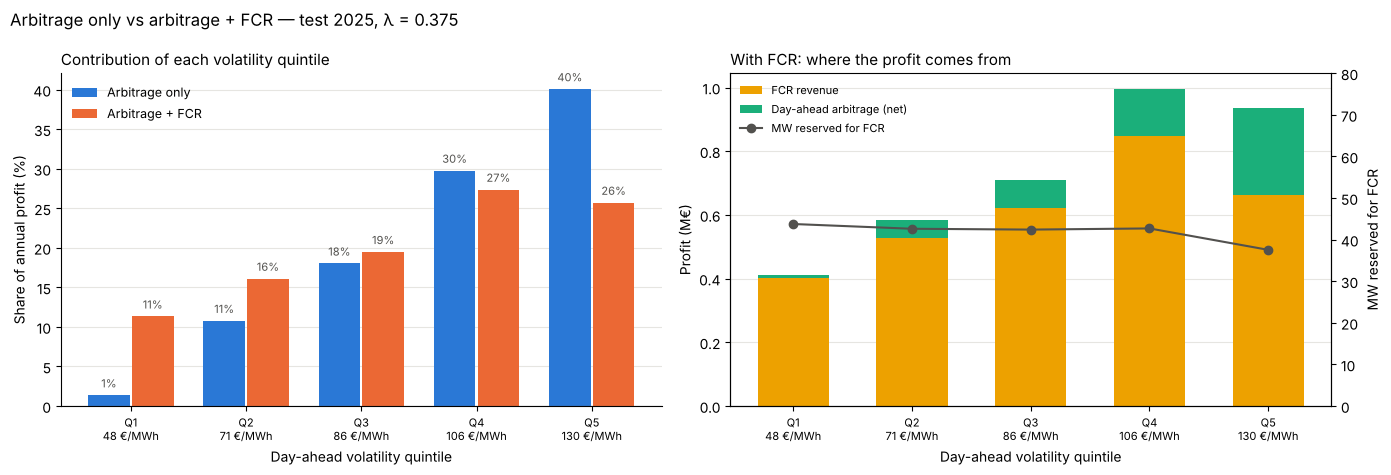

In [14]:
test_fcr = split_period(fcr, *config.TEST)
q = pd.qcut(spread.reindex(sorted(test_fcr["day"].unique())), 5, labels=[f"Q{i}" for i in range(1, 6)])
g = test_fcr[test_fcr["strategy"] == LAM_NAME].copy()
g["q"] = q.reindex(g["day"]).to_numpy()
by_q = g.groupby("q", observed=True).agg(profit_keur=("realized_eur", lambda x: x.sum() / 1000),
                                         fcr_keur=("fcr_revenue_eur", lambda x: x.sum() / 1000),
                                         avg_fcr_mw=("fcr_mw_mean", "mean"))
plots.plot_fcr_contribution(vq, volatility_quintiles(test_fcr, spread), by_q, LAM_NAME,
                            f"Arbitrage only vs arbitrage + FCR — test 2025, λ = {LAM:g}");

**FCR makes revenue much less dependent on volatility**: the calmest fifth of days brings 11% of the 2025 profit with
FCR, against 1% with arbitrage only.

## 6. Conclusions and limitations

1. A simple forecast captures **about 70% of the theoretical ceiling**.
2. Stochastic optimization only pays once risk is priced: **λ = 0.375 trades 2% of profit (not significant) for an
   18% better CVaR (significant)**, fewer loss days and less wear.
3. Risk sits on **calm days**, where the forecast error is as large as the spread.
4. A **drawdown budget** divides the 2022 drawdown by 4 against the deterministic strategy, but a well-chosen λ does as well without an extra rule.
5. **FCR dominates revenue, but the battery moves the French FCR price** (−26% at 50 MW in 2025). Accounting for it
   changes the strategy: part of the power is better used for arbitrage.

**Limitations.** Forecast from past prices only, scenarios too jagged (+20% spread) and too thin-tailed.
FCR impact is static (other bidders do not react) and activation energy is neglected. Daily horizon, hourly
prices, linear degradation. No intraday or aFRR.

**Possible improvements.** Forecast with fundamentals (load, wind, solar, gas) and quantiles, plugged into this
backtest; aFRR capacity (hourly, asymmetric); intraday as recourse.